In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

import testis_model as tm
importlib.reload(tm)

<module 'testis_model' from '/Users/connor/Documents/github/sperm-data-analysis/testis_model/__init__.py'>

In [2]:
importlib.reload(tm.gillespie)
importlib.reload(tm.data_processing)

n_stem = 1000
n_clones = 2
r_event = 36

p_asymmetric = (36 - 4)/36

eff_drift = r_event * (1 - p_asymmetric)
p_diff = 1 - p_asymmetric

sperm_per_diff = 1300
r_decay = 7
tau = 0.2

rng = np.random.default_rng()
init_freq = np.array([0.5, 0.5])
hmm = tm.gillespie.AdvancedTestisModel(n_stem, n_clones, r_event, p_diff, r_decay, tau, sperm_per_diff, init_freq)

In [3]:
# sample_times = np.sort(np.array(list(tm.data_processing.sample_map_int.values())))
sample_times = np.arange(5, 20)
sample_times = np.repeat(sample_times, 3)

In [4]:
# sample_times = np.arange(1, 16)
n_sperm = 371

samples, record, mean = hmm.simulate_gillespie(sample_times, n_sperm = 371, rng = rng, init_time = 4)

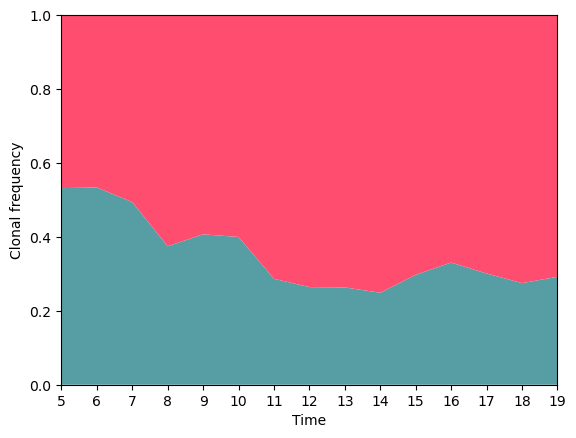

In [5]:
importlib.reload(tm.visualize)
tm.visualize.plot(samples)

In [6]:
importlib.reload(tm.likelihood)
lm = tm.likelihood.LikelihoodModel(n_stem)

In [7]:
lm.max_likelihood(samples, statistic = 4)

(np.float64(4.898365009035046),
 np.float64(-183.00912009437016),
 2.2257028814432713,
 12.31943406799234)

In [22]:
lm.likelihood(samples, 25.06, None, init_time = 4)

np.float64(-188.30468631141815)

In [23]:
lm.max_likelihood_null(samples, init_time = 4)

(np.float64(0.6447499906669395), np.float64(-704.1159418182624))

In [24]:
%%time
lm.max_likelihood(samples, init_time = 4, statistic = 4, f_cutoff=1e-10)

CPU times: user 1.46 s, sys: 190 ms, total: 1.65 s
Wall time: 1.65 s


(np.float64(4.933040098233252),
 np.float64(-182.96979500803513),
 2.234588082698934,
 12.50884678529142)

In [25]:
lm.likelihood(samples, 2.160412, None)

np.float64(-185.17348709716376)

In [26]:
lm.likelihood(samples, 14, 0.42)

np.float64(-184.7070450954015)

In [28]:
lm.likelihood(samples, 0, None)

np.float64(-903.1546759469553)

In [31]:
%%time
r_opt, l_max, lower, upper = lm.max_likelihood(samples, init_time = 4, statistic = 4)
print(f'{r_opt:.3f}, {l_max:.3f}, {lower:.3f}, {upper:.3f}')

4.933, -182.970, 2.235, 12.509
CPU times: user 1.46 s, sys: 191 ms, total: 1.65 s
Wall time: 1.65 s


In [33]:
lm.likelihood(samples, 6.349, None, init_time = 4)

np.float64(-183.1378158000233)

In [32]:
%%time
r_opt, l_max, lower, upper = lm.max_likelihood(samples, init_time = 4)
print(f'{r_opt:.3f}, {l_max:.3f}, {lower:.3f}, {upper:.3f}')

4.933, -182.970, 2.788, 9.349
CPU times: user 1.58 s, sys: 235 ms, total: 1.81 s
Wall time: 1.82 s
